# Runner – étapes 1 à 3 sur PARHAF

Lance les scripts du dossier `MyDrive/pfe/code`. Le code ne se modifie pas ici : on l'édite dans les fichiers `.py` et le `config.yaml`.

| Section | GPU |
| --- | --- |
| 0. Installation | non |
| 1. Caractérisation du corpus | non |
| 2. Serveur vLLM | **oui** |
| 3. Baseline (étape 2) | **oui** pour la génération |
| 4. Jeu de référence (étape 3) | **oui** pour l'extraction |

Si Colab coupe : relancer la section 0, puis le serveur, puis le script interrompu. Il reprend là où il s'était arrêté.

## 0. Installation

In [1]:
import os
from google.colab import drive, userdata

drive.mount("/content/drive")
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")   # Secrets Colab (icône clé)

CODE_DIR = "/content/drive/MyDrive/pfe/code"
OUT_DIR = "/content/drive/MyDrive/pfe/outputs"   # doit correspondre à paths.output_dir du config.yaml
%cd {CODE_DIR}

Mounted at /content/drive
/content/drive/MyDrive/pfe/code


In [3]:
from huggingface_hub import whoami

print(whoami()["name"])   # doit afficher votre nom d'utilisateur Hugging Face


ROJO47


In [2]:
!pip install -q -r requirements.txt
!pip freeze > requirements.lock.txt   # versions exactes, à archiver avec chaque run
# Si PyTorch a été remplacé par l'installation de vLLM : Exécution > Redémarrer la session,
# puis relancer uniquement la cellule précédente (montage de Drive).

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.2.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.


## 1. Caractérisation du corpus (étape 1)

In [5]:
!python step1_explore.py

config.json: 100% 737/737 [00:00<00:00, 1.93MB/s]
tokenizer_config.json: 100% 1.47k/1.47k [00:00<00:00, 548kB/s]
tokenizer.json: 100% 1.80M/1.80M [00:00<00:00, 22.8MB/s]

tokenizer.model: downloading bytes:   0% 0.00/493k [00:00<?, ?B/s]
tokenizer.model: downloading bytes: 100% 339k/339k [00:00<00:00, 409kB/s, 33.3kB/s  ]
tokenizer.model: reconstructing file: 100% 493k/493k [00:00<00:00, 596kB/s, 48.5kB/s  ]
special_tokens_map.json: 100% 414/414 [00:00<00:00, 989kB/s]
README.md: 100% 22.2k/22.2k [00:00<00:00, 28.0MB/s]

data/train-00000-of-00001.parquet: downloading bytes:  11% 1.01M/9.25M [00:00<00:05, 1.61MB/s]
data/train-00000-of-00001.parquet: downloading bytes: 100% 9.20M/9.20M [00:00<00:00, 11.5MB/s,  901kB/s  ]
data/train-00000-of-00001.parquet: reconstructing file: 100% 9.25M/9.25M [00:00<00:00, 11.6MB/s,  907kB/s  ]
Generating train split: 100% 4254/4254 [00:00<00:00, 8702.25 examples/s]
# Étape 1 – Caractérisation de PARHAF

Patients : 4254 | Documents : 6185 | Coût fixe du p

# Étape 1 – Caractérisation de PARHAF

Patients : 4254 | Documents : 6185 | Coût fixe du prompt : 89 tokens | Tokens par mot : 2.57

## Par type de document
| type         |    n |   mots_median |   tokens_median |   tokens_p90 |   tokens_max |   pct_tient_256 |   pct_tient_512 |
|:-------------|-----:|--------------:|----------------:|-------------:|-------------:|----------------:|----------------:|
| CRH          | 3563 |         496   |          1278   |       2574   |         7889 |            70.4 |            59.7 |
| CRC          | 1079 |         232   |           534   |        989.4 |         7090 |            98.8 |            96.8 |
| CRO          |  889 |         220   |           557   |       1008.4 |         2629 |            97.6 |            96.2 |
| ANAPATH      |  433 |         261   |           739   |       1463.6 |         3065 |            93.3 |            89.6 |
| ACCOUCHEMENT |   74 |         201   |           515.5 |       1178.1 |         1367 |           100   |           100   |
| MATERNITE    |   74 |         117.5 |           321.5 |        548.4 |          620 |           100   |           100   |
| URGENCES     |   73 |         345   |           905   |       1315.2 |         1604 |           100   |            95.9 |

## Patients dont tous les documents tiennent dans la fenêtre (%)
- sortie réservée 256 : 64.3 %
- sortie réservée 512 : 52.0 %

## Remplissage de structured_abstract (%)
|                 |    0 |
|:----------------|-----:|
| abs_diagnostic  | 85   |
| abs_acte        | 24.2 |
| abs_mode_entree | 37.6 |
| abs_mode_sortie | 37.6 |
| abs_duree       | 83.1 |

## Combinaisons de documents par patient
| doc_types                       |   count |
|:--------------------------------|--------:|
| CRH                             |    2672 |
| CRC+CRH+CRO                     |     887 |
| ANAPATH                         |     421 |
| CRC                             |     192 |
| ACCOUCHEMENT+MATERNITE+URGENCES |      72 |
| ANAPATH+ANAPATH                 |       6 |
| ACCOUCHEMENT+CRH+MATERNITE      |       2 |
| CRH+CRO                         |       1 |
| CRH+CRO+URGENCES                |       1 |

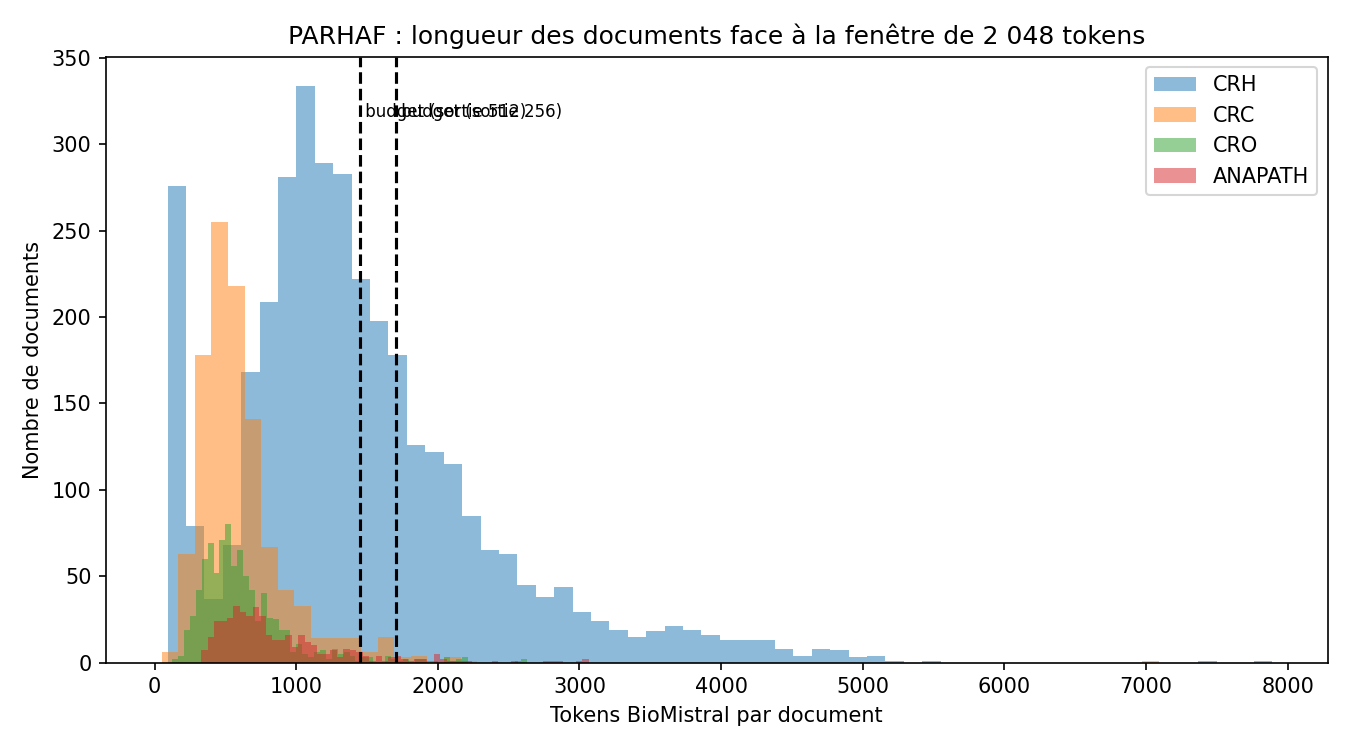

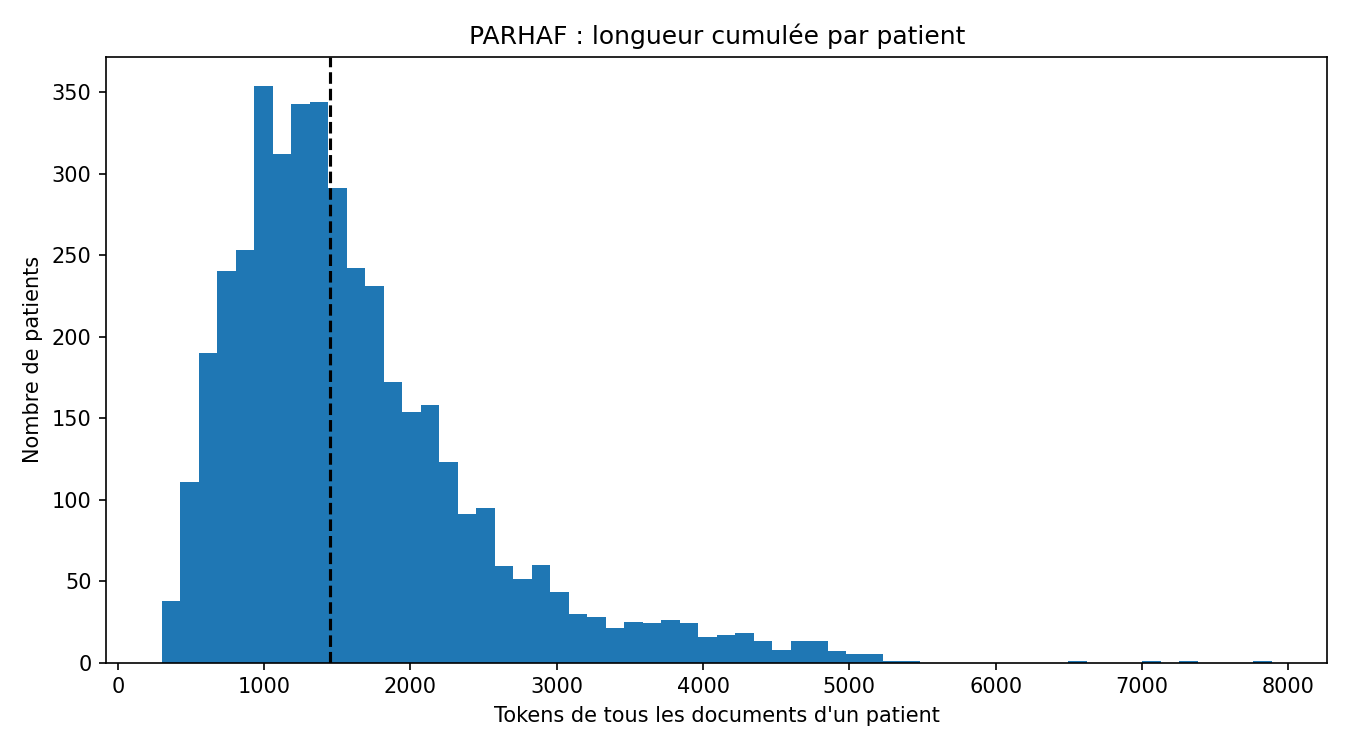

In [6]:
from IPython.display import Image, Markdown, display

display(Markdown(open(f"{OUT_DIR}/step1/summary.md", encoding="utf-8").read()))
display(Image(f"{OUT_DIR}/step1/tokens_par_type.png"))
display(Image(f"{OUT_DIR}/step1/tokens_par_patient.png"))

## 2. Serveur vLLM

Lancé en arrière-plan. Les scripts attendent eux-mêmes qu'il soit prêt (2 à 3 minutes). Ne pas ouvrir `Biomistrale.ipynb` dans la même session.

In [12]:
!nohup vllm serve BioMistral/BioMistral-7B-AWQ-QGS128-W4-GEMM \
    --quantization awq --max-model-len 2048 --enforce-eager --seed 42 \
    --port 8000 > /content/vllm.log 2>&1 &

In [14]:
# Vérifier l'état du serveur (relancer la cellule jusqu'à voir « Application startup complete »)
!tail -n 15 /content/vllm.log
!curl -s -o /dev/null -w "health: %{http_code}\n" http://localhost:8000/health

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

In [15]:
import subprocess, time, requests

for _ in range(60):   # jusqu'à 10 minutes

    try:

        if requests.get("http://localhost:8000/health", timeout=5).status_code == 200:

            print("Serveur prêt.")

            break

    except requests.ConnectionError:

        pass

    alive = subprocess.run(["pgrep", "-f", "vllm serve"], capture_output=True).returncode == 0

    if not alive:

        print("Le serveur s'est arrêté. Fin du log :")

        print(subprocess.run(["tail", "-n", "40", "/content/vllm.log"], capture_output=True, text=True).stdout)

        break

    time.sleep(10)

else:

    print("Toujours pas prêt après 10 min : envoyer la fin de /content/vllm.log")


Serveur prêt.


## 3. Baseline CRH → résumé JSON (étape 2)

Commencer par tester avec `n_patients: 3` dans `config.yaml` et vérifier les premières lignes, puis repasser à 40.

In [25]:
!python step2_generate.py

40 patients sélectionnés, 0 déjà traités.
[1/40] CANCERO-ADULTE-00025 -> ok (29.819 s)
[2/40] CANCERO-ADULTE-00102 -> skipped_context_overflow (- s)
[3/40] CANCERO-ADULTE-00115 -> invalid_output (32.689 s)
[4/40] CANCERO-ADULTE-00129 -> ok (27.761 s)
[5/40] CANCERO-ADULTE-00138 -> skipped_context_overflow (- s)
[6/40] CARDIOLOGIE-00062 -> skipped_context_overflow (- s)
[7/40] CARDIOLOGIE-00116 -> skipped_context_overflow (- s)
[8/40] CHIR-ORTHO-ET-TRAUMATO-00024 -> ok (27.537 s)
[9/40] CHIR-ORTHO-ET-TRAUMATO-00073 -> ok (29.525 s)
[10/40] CHIR-ORTHO-ET-TRAUMATO-00253 -> ok (31.465 s)
[11/40] CHIR-CARDIO-VASC-00019 -> skipped_context_overflow (- s)
[12/40] CHIRURGIE-VISCERALE-00215 -> invalid_output (34.937 s)
[13/40] CHIRURGIE-VISCERALE-00354 -> ok (23.514 s)
[14/40] CHIRURGIE-VISCERALE-00365 -> ok (23.927 s)
[15/40] CHIRURGIE-VISCERALE-00383 -> ok (24.005 s)
[16/40] CHIRURGIE-VISCERALE-00510 -> ok (30.392 s)
[17/40] GYNECOLOGIE-00045 -> ok (32.975 s)
[18/40] GYNECOLOGIE-00294 -> ok (2

In [26]:
import json
import yaml

cfg = yaml.safe_load(open("config.yaml", encoding="utf-8"))
run_file = f"{OUT_DIR}/step2/{cfg['step2']['run_name']}.jsonl"
with open(run_file, encoding="utf-8") as f:
    first = json.loads(f.readline())
print("Statut :", first["status"], "| tokens estimés :", first["prompt_tokens_est"])
print(json.dumps(first.get("prediction") or first.get("raw_output"), ensure_ascii=False, indent=2))

Statut : ok | tokens estimés : 1414
{
  "diagnostic_principal": [
    {
      "code": "C34",
      "description": "Carcinome bronchique non à petites cellules"
    }
  ],
  "acte_principal": [
    {
      "code": "Z08",
      "description": "Consultation spécialisée: Oncologie thoracique"
    }
  ],
  "mode_entree": "Hospitalisation",
  "mode_sortie": "Sortie contre avis médical",
  "duree_sejour_jours": 1,
  "antecedents": [
    "Cancer de l'oropharynx",
    "Carcinome bronchique non à petites cellules"
  ],
  "traitements_sortie": [
    "Radiothérapie",
    "Carboplatine et Paclitaxel",
    "Atezolizumab",
    "Pemetrexed"
  ],
  "synthese": "Patiente âgée de 59 ans, suivie pour cancer de l'oropharynx traité par radiothérapie et chimiothérapie, puis pour carcinome bronchique non à petites cellules traité par radiothérapie et chimiothérapie, hospitalisée pour consultation spécialisée en oncologie thoracique et mise sous Pemetrexed. La patiente rapporte une douleur scapulaire gauche, a

In [27]:
!python step2_evaluate.py

{
  "run_name": "test_40patients_v1",
  "n_patients": 40,
  "pct_json_valide": 50.0,
  "pct_sortie_invalide": 12.5,
  "pct_depassement_contexte": 37.5,
  "diag_code_exact_pct": 5.0,
  "diag_code_3car_pct": 20.0,
  "diag_sim_moyenne": 0.477,
  "acte_code_exact_pct": 0.0,
  "acte_sim_moyenne": 0.392,
  "entree_sim_moyenne": 0.25,
  "sortie_sim_moyenne": 0.282,
  "duree_exacte_pct": 38.9,
  "duree_plus_moins_1_pct": 88.9,
  "pct_nombres_non_sources": 11.8,
  "pct_codes_non_sources": 100.0,
  "latence_moyenne_s": 27.17,
  "latence_p90_s": 31.62,
  "tokens_entree_moyen": 987.5,
  "tokens_sortie_moyen": 408.0,
  "n_a_relire": 20
}


In [20]:
import json

with open(run_file, encoding="utf-8") as f:

    records = [json.loads(line) for line in f]

for r in records:

    if r["status"] != "invalid_output":

        continue

    print("=" * 80)

    print(r["patient_id"], "| tokens entrée :", r["prompt_tokens_est"], "| usage :", r["usage"])

    print("--- Erreur (début) ---")

    print(r["error"][:600])

    print("--- Sortie brute : début ---")

    print(r["raw_output"][:800])

    print("--- Sortie brute : fin ---")

    print(r["raw_output"][-400:])


CHIR-ORTHO-ET-TRAUMATO-00073 | tokens entrée : 495 | usage : {'input_tokens': 495, 'output_tokens': 512, 'total_tokens': 1007, 'input_token_details': {}, 'output_token_details': {}}
--- Erreur (début) ---
1 validation error for ResumeSejour
  Invalid JSON: EOF while parsing a list at line 2 column 1526 [type=json_invalid, input_value='{\n"diagnostic_principal..." , "pas de traitement"', input_type=str]
    For further information visit https://errors.pydantic.dev/2.14/v/json_invalid
--- Sortie brute : début ---
{
"diagnostic_principal": [{"code": "CE", "description": "CE"}] , "acte_principal": [{"code": "ablation", "description": "ablation"}] , "mode_entree": "ambulatoire" , "mode_sortie": "ambulatoire" , "duree_sejour_jours": 1 , "antecedents": [ "tabagisme" , "pas de traitement" , "pas de traitement" , "pas de traitement" , "pas de traitement" , "pas de traitement" , "pas de traitement" , "pas de traitement" , "pas de traitement" , "pas de traitement" , "pas de traitement" , "pas de 

In [28]:
import pandas as pd

df = pd.read_csv(f"{OUT_DIR}/step2/{cfg['step2']['run_name']}_par_patient.csv")
df[df["a_relire"]]   # cas à vérifier à la main avant toute conclusion

,patient_id,specialty,diag_code_exact,diag_code_3car,diag_sim,acte_code_exact,acte_code_3car,acte_sim,entree_sim,sortie_sim,...,n_nombres,n_nombres_non_sources,nombres_non_sources,n_codes,n_codes_non_sources,codes_non_sources,latence_s,tokens_entree,tokens_sortie,a_relire
0,CANCERO-ADULTE-00025,CANCERO ADULTE,False,True,0.453608,NaN,NaN,NaN,NaN,NaN,...,1,1,59,2,2,"C34, Z08",29.819,1414,429,True
1,CANCERO-ADULTE-00129,CANCERO ADULTE,False,False,0.545455,NaN,NaN,NaN,NaN,NaN,...,5,0,NaN,2,2,"C2, D00",27.761,985,408,True
2,CHIR-ORTHO-ET-TRAUMATO-00024,CHIR ORTHO ET TRAUMATO,False,False,0.588235,False,False,0.382979,NaN,NaN,...,6,0,NaN,2,2,"M82, Z960",27.537,472,422,True
3,CHIR-ORTHO-ET-TRAUMATO-00073,CHIR ORTHO ET TRAUMATO,False,False,0.442308,False,False,0.360360,NaN,NaN,...,7,2,"1, 60",2,2,"L697, Z030",29.525,583,456,True
4,CHIR-ORTHO-ET-TRAUMATO-00253,CHIR ORTHO ET TRAUMATO,False,False,0.361446,False,False,0.434783,NaN,NaN,...,5,0,NaN,2,2,"M46, Z967",31.465,363,487,True
5,CHIRURGIE-VISCERALE-00354,CHIRURGIE VISCERALE,False,False,0.195804,False,False,0.349206,0.170213,0.285714,...,3,0,NaN,2,2,"J04, K86",23.514,1516,341,True
6,CHIRURGIE-VISCERALE-00365,CHIRURGIE VISCERALE,False,False,0.322581,False,False,0.400000,0.200000,0.105263,...,3,0,NaN,2,2,"K967, Z041",23.927,306,363,True
7,CHIRURGIE-VISCERALE-00383,CHIRURGIE VISCERALE,False,True,0.641509,False,False,0.337662,0.235294,0.325581,...,3,0,NaN,3,3,"J99, K85, Z03",24.005,979,364,True
8,CHIRURGIE-VISCERALE-00510,CHIRURGIE VISCERALE,False,False,0.400000,False,False,0.459893,0.200000,0.105263,...,14,10,"01, 01.0, 01.1, 03.0, 03.1, 03.2, 06, 07.2, 15...",2,2,"J041, K869",30.392,403,462,True
9,GYNECOLOGIE-00045,GYNECOLOGIE,False,False,0.892857,False,False,0.495050,0.235294,0.325581,...,15,0,NaN,2,2,"N80, Z370",32.975,940,487,True


## 4. Jeu de référence (étape 3)

1. Pré-extraction (GPU) ;
2. arrêt du serveur pour libérer le GPU ;
3. correction manuelle des fichiers `outputs/step3_gold/*.json` selon le guide du README ;
4. validation (sans GPU, à relancer autant de fois que nécessaire).

In [ ]:
!python step3_extract.py

In [ ]:
# Arrêter le serveur quand la génération est finie (libère le GPU et le quota Colab)
!pkill -f "vllm serve" && echo "Serveur arrêté"

In [ ]:
!python step3_validate.py